In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import scipy 
from plotting_helper import *
from joblib import Parallel, delayed
from parameters import * 
%matplotlib inline

figures_path = 'figures/'
palette = plt.rcParams['axes.prop_cycle'].by_key()['color']  

In [32]:
def diff_assump(parameters, state_var, dt , elong_fun):

    
    x_vec = state_var[0]   #free mRNA concentrations
    xr_vec = state_var[1]  # bound mRNA ribosome concentrations
    y_vec = state_var[2]   #protein concentrations
    r = parameters['R'] - np.sum(xr_vec)  #concentration of free ribosomes, separate pool for each
    y_free = parameters['Y_max'] - np.sum(y_vec) 


    new_x_vec = x_vec + dt * (-parameters['α']  * r * x_vec  + parameters['β']* xr_vec * y_free)
    new_xr_vec = xr_vec + dt * (parameters['α'] * r *  x_vec - parameters['β'] * xr_vec * y_free)
    new_y_vec = y_vec + dt * (parameters['β']  * xr_vec * y_free - parameters['γ'] * y_vec)
    #reinitiation

    return new_x_vec, new_xr_vec, new_y_vec


def simulation_wrapper_parallel(params, sim_time, dt, Rs): 
    
    parameters = dict()
    parameters['α'] = params[0]
    parameters['β'] = params[1] / l_samples
    parameters['γ'] = γ
    parameters['l'] = l_samples
    parameters['lp'] = stiffness_fun(parameters['l'],stiffness_fac)
    parameters['Y_max'] =  N
    res = np.zeros([Rs.shape[0],3,N ])
    
    for r in range(Rs.shape[0]): 
        parameters['R'] = Rs[r]


        x0 = np.ones([N])*x_init
        init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 

        next_t = init_state

        for t in range(int(sim_time/dt)):
            next_t = diff_assump(parameters, next_t, dt, R_fernandes)
        res[r] = next_t

    return res

Here we test the influence of the overall setting of alpha and beta for the competition.
We reduce number of species show the effect clearly and can translate it better to the analytical results. 

In [33]:
α_samples = np.linspace(0.0001, 0.1, 20) #this ensures that we will have cases in which α < β
β_samples = np.linspace(0.0001, 0.1, 18)

In [35]:
sim_time = 150 
dt = 0.001

results = Parallel(n_jobs=-1)(delayed(simulation_wrapper_parallel)([a,b], sim_time, dt,Rs) for a in α_samples for b in β_samples)
results = np.asarray(results)

res_inter = np.reshape(results, (α_samples.shape[0], β_samples.shape[0], Rs.shape[0], 3, N))

np.save('diff_data/elongation_initiation_interaction.npy',res_inter)

NameError: name 'res_inter' is not defined

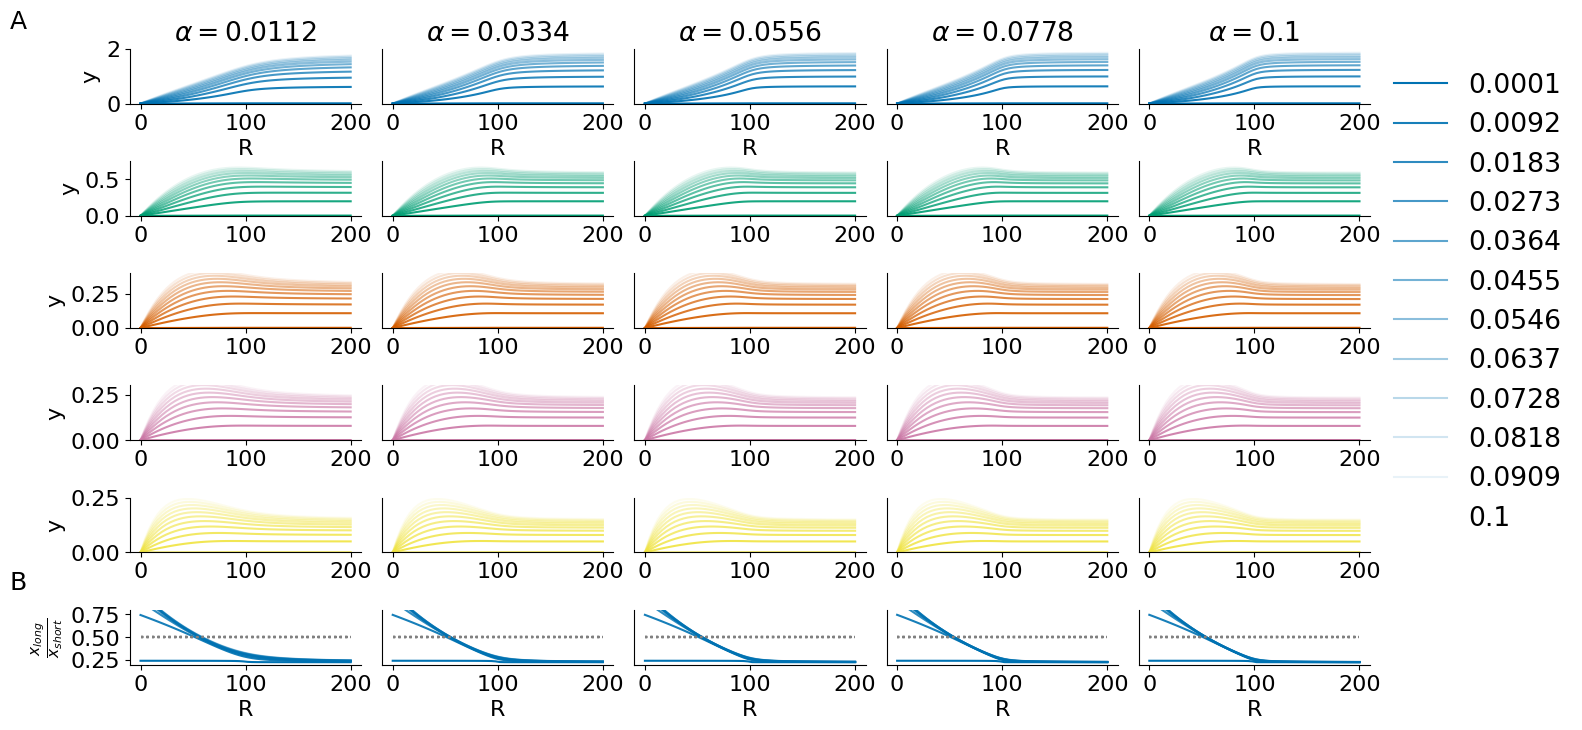

In [5]:
layout = '''
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    AAAAAAAAAA
    BBBBBBBBBB
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1,0.1,1,0.1,1,0.1,1,0.1,1]
width_ratios = [1,1,1,1,1,1,1,1,1,1]

specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'AB':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='AB', postfix='', offset_left=1.2)
for a in list('AB'):
    axes[a].set_axis_off()
    
ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']
avs = np.linspace(0,1, β_samples.shape[0])[::-1]

 
for i in range(1,α_samples.shape[0],2):
    ax1 = fig.add_subplot(gs[0,i-1:i+2-1])
    ax2 = fig.add_subplot(gs[2,i-1:i+2-1])
    ax3 = fig.add_subplot(gs[4,i-1:i+2-1])
    ax4 = fig.add_subplot(gs[6,i-1:i+2-1])
    ax5 = fig.add_subplot(gs[8,i-1:i+2-1])
    ax = fig.add_subplot(gs[10,i-1:i+2-1])
    for j in range(0,β_samples.shape[0]):
        av1 = np.mean(results[i * β_samples.shape[0] +j,:, 2,s_1k], axis = 0)
        av2 = np.mean(results[i * β_samples.shape[0] +j,:, 2,s_2k], axis = 0)
        av3 = np.mean(results[i * β_samples.shape[0] +j,:, 2,s_3k], axis = 0)
        av4 = np.mean(results[i * β_samples.shape[0] +j,:, 2,s_4k], axis = 0)
        av5 = np.mean(results[i * β_samples.shape[0] +j,:, 2,b_4k], axis = 0)
        
        rat1 = np.mean(results[i * β_samples.shape[0] +j,:, 2,long_ind], axis = 0)/np.mean(results[i * β_samples.shape[0] +j,:, 2,short_ind], axis = 0)

        ax1.plot(Rs, av1, label = np.round(β_samples[j],4), color= palette[0], alpha = avs[j])
        ax2.plot(Rs, av2, label = β_samples[j], color = palette[1], alpha = avs[j])
        ax3.plot(Rs, av3, label = β_samples[j], color = palette[2], alpha = avs[j])
        ax4.plot(Rs, av4, label = β_samples[j], color = palette[3], alpha = avs[j])
        ax5.plot(Rs, av5, label = β_samples[j], color =palette[4], alpha = avs[j])
        ax.plot(Rs, rat1, label = β_samples[j], color = palette[0], alpha = avs[j])
        ax.plot(Rs, Rs*0 + 0.5, linestyle = ':', color = 'grey')
    ax1.set_title('$\\alpha =$'+str(np.round(α_samples[i],4)))
    ax1.set_ylim(0,2)
    ax2.set_ylim(0,0.75)
    ax3.set_ylim(0,0.4)
    ax4.set_ylim(0,0.3)
    ax5.set_ylim(0,0.25)
    ax.set_ylim(0.2,0.8)
    ax1.set_xlabel('R')
    ax.set_xlabel('R')
    
    if (i-1) > 0: 
        ax.set_yticks([])
        ax1.set_yticks([])
        ax2.set_yticks([])
        ax3.set_yticks([])
        ax4.set_yticks([])
        ax5.set_yticks([])
    else: 
        ax1.set_ylabel('y')
        ax2.set_ylabel('y')
        ax3.set_ylabel('y')
        ax4.set_ylabel('y')
        ax5.set_ylabel('y')
        ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
    

    clear_axes(ax)
    clear_axes(ax1)
    clear_axes(ax2)
    clear_axes(ax3)
    clear_axes(ax4)
    clear_axes(ax5)
handles, labels = ax.get_legend_handles_labels()
ax1.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
plt.savefig(figures_path+'fig5_parameter_exploration.pdf')      
plt.show()



In [6]:
def calc_comp_score(dat1,dat2, diff_axis, mean_axis): 
    
    #compute differences along correct axis
    differences_along_R1= np.diff(dat1, axis = diff_axis)
    differences_along_R1[np.abs(differences_along_R1) < 1e-10] = np.nan
    differences_along_R2= np.diff(dat2, axis = diff_axis)
    differences_along_R2[np.abs(differences_along_R2) < 1e-10] = np.nan
    #comput the mean
    if mean_axis >= 0:
        means1 = np.nanmean(differences_along_R1, axis = mean_axis)
        means2 = np.nanmean(differences_along_R2, axis = mean_axis)
        return means1/means2
    else: 
        return differences_along_R1/differences_along_R2

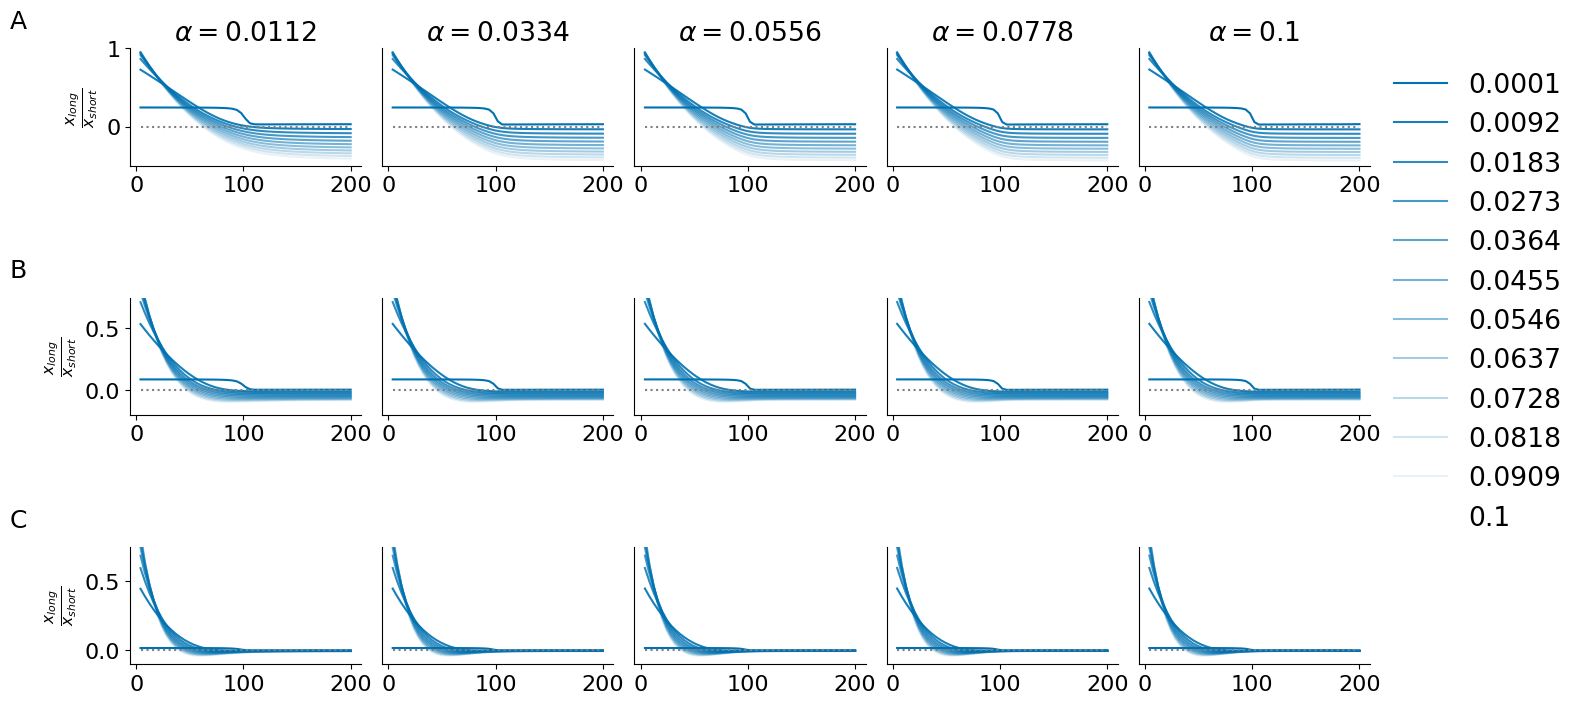

In [8]:
layout = '''
    AAAAAAAAAA
    AAAAAAAAAA
    BBBBBBBBBB
    BBBBBBBBBB
    CCCCCCCCCC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1,0.1,1]
width_ratios = [1,1,1,1,1,1,1,1,1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()
    
res_inter = np.reshape(results, (α_samples.shape[0], β_samples.shape[0], Rs.shape[0], 3, N))
avs = np.linspace(0,1, β_samples.shape[0])[::-1]

 
for i in range(1,α_samples.shape[0],2):
    ax1 = fig.add_subplot(gs[0,i-1:i+2-1])
    ax2 = fig.add_subplot(gs[2,i-1:i+2-1])
    ax3 = fig.add_subplot(gs[4,i-1:i+2-1])
    for j in range(0,β_samples.shape[0]):
        ax1.plot(Rs[1:], calc_comp_score(res_inter[i,j,:, 2,long_ind], res_inter[i,j,:, 2,short_ind], diff_axis = 1, mean_axis = 0), color= palette[0], alpha = avs[j], label = np.round(β_samples[j],4))
        ax2.plot(Rs[1:], calc_comp_score(res_inter[i,j,:, 2,b_4k], res_inter[i,j,:, 2,s_1k], diff_axis = 1, mean_axis = 0), color= palette[0], alpha = avs[j], label = np.round(β_samples[j],4))
        ax3.plot(Rs[1:], calc_comp_score(res_inter[i,j,:, 2,-1], res_inter[i,j,:, 2,0], diff_axis = 0, mean_axis = -1), color= palette[0], alpha = avs[j], label = np.round(β_samples[j],4))
    ax1.set_title('$\\alpha =$'+str(np.round(α_samples[i],4)))
    ax1.plot(Rs[1:], Rs[1:]*0, linestyle = ':', color = 'grey')
    ax2.plot(Rs[1:], Rs[1:]*0, linestyle = ':', color = 'grey')
    ax3.plot(Rs[1:], Rs[1:]*0, linestyle = ':', color = 'grey')
    
    ax1.set_ylim(-0.5,1)
    ax2.set_ylim(-0.2,0.75)
    ax3.set_ylim(-0.1,0.75)
    
    if (i-1) > 0: 
        ax.set_yticks([])
        ax1.set_yticks([])
        ax2.set_yticks([])
        ax3.set_yticks([])
        ax4.set_yticks([])
        ax5.set_yticks([])
    else: 
        ax1.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
        ax2.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
        ax3.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
    

    clear_axes(ax1)
    clear_axes(ax2)
    clear_axes(ax3)
handles, labels = ax.get_legend_handles_labels()
ax1.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
#plt.savefig(figures_path+'fig5_parameter_exploration.pdf')      
plt.show()



In [41]:
α_samples = np.linspace(0.0001, 0.1, 20) #this ensures that we will have cases in which α < β
β_samples = np.linspace(0.0001, 0.1, 18)

sim_time = 150 
dt = 0.001

Rs_inter = np.array([50,75,100])

results = Parallel(n_jobs=-1)(delayed(simulation_wrapper_parallel)([a,b], sim_time, dt,Rs_inter) for a in α_samples for b in β_samples)
results = np.asarray(results)

res_inter = np.reshape(results, (α_samples.shape[0], β_samples.shape[0], Rs_inter.shape[0], 3, N))

np.save('diff_data/elongation_initiation_interaction_subsampled.npy',res_inter)

In [38]:
###here we try some different way of visualising the data 

#load data
interact_dat = np.load('diff_data/elongation_initiation_interaction_subsampled.npy')
#shape: (10, 12, 50, 3, 100)

comp_c = calc_comp_score(interact_dat[:,:,:,2, long_ind], interact_dat[:,:,:,2, short_ind], 2,3)

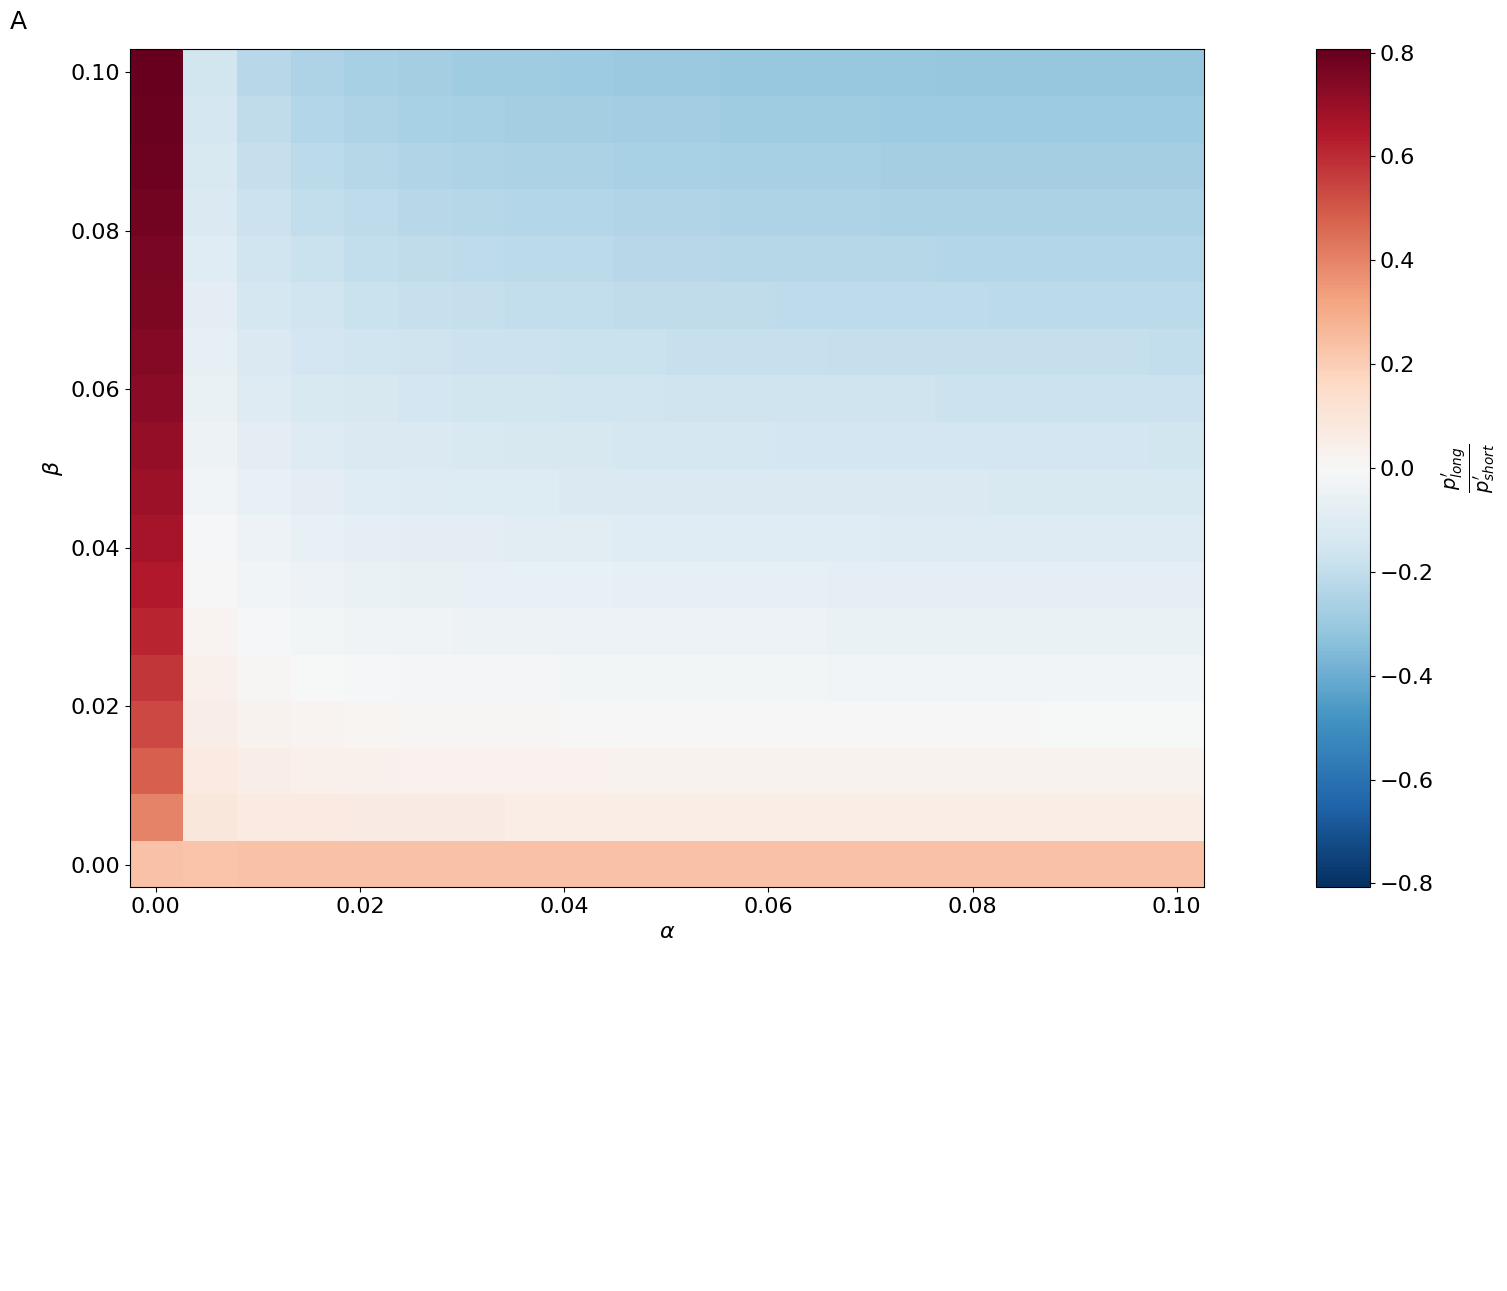

In [39]:
α_samples = np.linspace(0.0001, 0.1, 20) #this ensures that we will have cases in which α < β
β_samples = np.linspace(0.0001, 0.1, 18)


layout = '''
AA
AA
'''

fig = plt.figure(figsize=(16, 16))

height_ratios = [2,0.1]
width_ratios = [1,.05]

specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'A':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='A', postfix='', offset_left=1.2)
for a in list('A'):
    axes[a].set_axis_off()
    
ax = fig.add_subplot(gs[0:1,0])
#ax.set_yscale('log')
cmax = np.max(np.abs([np.min(comp_c), np.max(comp_c)]))
hm = ax.pcolor(α_samples,β_samples, comp_c[:,:,0].T, cmap = 'RdBu_r',shading='nearest',vmin = -cmax, vmax = cmax)#, extent = [Ys[0], Ys[-1], Rs[1], Rs[-1]])
hm_ax = fig.add_subplot(gs[0:1,1])
cbar = fig.colorbar(hm, hm_ax)
cbar.ax.set_ylabel("$\\frac{p_{long}'}{p_{short}'}$", fontsize = 20)
ax.set_xlabel('$\\alpha$')
ax.set_ylabel('$\\beta$')

#plt.savefig(figures_path+'fig5_heatmap_alphabeta_interaction.pdf')

plt.show()